Defaulting to user installation because normal site-packages is not writeable
Размер данных: (284807, 31)
Мошеннических транзакций: 492
В тесте: 85443 | мошеннических: 148


,Порог,Macro F1
Модель,,
Bagging,0.40,0.9219
Random Forest,0.36,0.9033
CatBoost,0.99,0.8931
LightGBM,0.99,0.5673


Лучший результат на тесте: Bagging


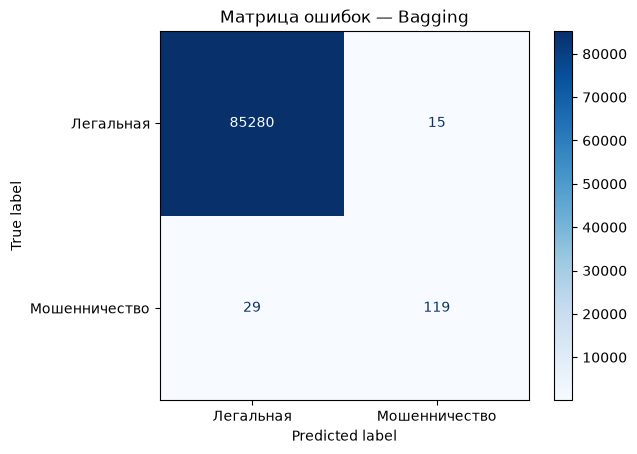

In [2]:
!pip install lightgbm catboost kagglehub

from pathlib import Path
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, ConfusionMatrixDisplay
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

csv = Path(kagglehub.dataset_download('mlg-ulb/creditcardfraud')) / 'creditcard.csv'

df = pd.read_csv(csv)
X = df.drop(columns='Class')
y = df.Class

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=df.Class, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42
)
print('Размер данных:', df.shape)
print('Мошеннических транзакций:', y.sum())
print('В тесте:', len(y_test), '| мошеннических:', y_test.sum())

models = {
    'Bagging': BaggingClassifier(
        estimator=DecisionTreeClassifier(max_depth=10, min_samples_leaf=2),
        n_estimators=50, n_jobs=-1, random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, max_depth=12, class_weight='balanced_subsample',
        n_jobs=-1, random_state=42
    ),
    'LightGBM': LGBMClassifier(
        n_estimators=200, learning_rate=0.05, num_leaves=15,
        is_unbalance=True, verbosity=-1, random_state=42
    ),
    'CatBoost': CatBoostClassifier(
        iterations=300, depth=6, learning_rate=0.05,
        auto_class_weights='Balanced', verbose=False, random_seed=42
    )
}

thresholds = np.r_[0.001, 0.005, np.arange(0.01, 1.0, 0.01)]
rows = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    p_val = model.predict_proba(X_val)[:, 1]
    threshold = max(thresholds, key=lambda t: f1_score(y_val, p_val >= t, average='macro'))
    y_pred = (model.predict_proba(X_test)[:, 1] >= threshold).astype(int)
    predictions[name] = y_pred
    rows.append([name, threshold, f1_score(y_test, y_pred, average='macro')])

results = pd.DataFrame(rows, columns=['Модель', 'Порог', 'Macro F1']).set_index('Модель')
results = results.sort_values('Macro F1', ascending=False)
display(results.round(4))

best = results.index[0]
print('Лучший результат на тесте:', best)
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions[best], display_labels=['Легальная', 'Мошенничество'],
    cmap='Blues', values_format='d'
)
plt.title(f'Матрица ошибок — {best}')
plt.show()